# Load Xenium Output and Save as SpatialData and AnnData

In [ ]:
import os
from spatialdata_io import xenium
from Xenium_5K_IPF_constants import SAMPLES_SYMBOLS, WORK_PATH, PROSEG_PATH  # import a python file containing constants

# Ouput directories
os.makedirs(f"{WORK_PATH}SpatialData", exist_ok=True)
os.makedirs(f"{WORK_PATH}AnnData", exist_ok=True)

In [ ]:
for ss in SAMPLES_SYMBOLS:
    # load xenium/Proseg output data
    sdata = xenium(f"{PROSEG_PATH}{ss}/{ss}/outs",
                   cells_as_circles=False, 
                   cells_labels=False, 
                   nucleus_labels=False, 
                   cells_boundaries=True, 
                   nucleus_boundaries=False,
                   transcripts=False,
                   morphology_focus=False, 
                   morphology_mip=False, 
                   aligned_images=False)

    adata = sdata.tables["table"]

    sdata.write(f"{WORK_PATH}SpatialData/{ss}", overwrite=True)
    adata.write(f"{WORK_PATH}AnnData/{ss}.h5ad")

# Integrate AnnData

In [8]:
import scanpy as sc
import anndata
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from Xenium_5K_IPF_constants import SAMPLES_SYMBOLS, WORK_PATH
%matplotlib ipympl
plt.rcParams["font.family"] = "Fira Sans" 
# Option
sc.settings.verbosity = 3

In [2]:
adata_list=[sc.read_h5ad(f"{WORK_PATH}AnnData/{ss}.h5ad") for ss in SAMPLES_SYMBOLS]
for n, ss in enumerate(SAMPLES_SYMBOLS):
    adata_list[n].obs_names=[c_id[:-1]+f"{n}" for c_id in adata_list[n].obs["cell_id"]]
    adata_list[n].obs["sample"]=ss
    

In [3]:
# Quality control
tc_p = 0.95  # Cut off the ratio of transcript_counts to total_counts
tc_c = 60  # The value of minimum transcript_counts 

for ad in adata_list:
    ad.obs["tc_ratio"]=ad.obs["transcript_counts"]/ad.obs["total_counts"]
    print(ad.obs["sample"].iloc[0]+":", "low_quality_counts", np.sum(ad.obs["tc_ratio"]< tc_p), "|", "transcript_counts", np.sum(ad.obs["transcript_counts"] < tc_c), "| total_cell_counts", ad.shape[0])

adata_list_qc=[ad[ad.obs["tc_ratio"] > tc_p] for ad in adata_list]
adata_list_qc=[ad[ad.obs["transcript_counts"] >= tc_c] for ad in adata_list_qc]

AF_s2: low_quality_counts 0 | transcript_counts 15018 | total_cell_counts 103736
FR_s1: low_quality_counts 0 | transcript_counts 12323 | total_cell_counts 111000
FR_s3: low_quality_counts 0 | transcript_counts 5719 | total_cell_counts 162606
FR_s4: low_quality_counts 0 | transcript_counts 4717 | total_cell_counts 86433
HC_s1: low_quality_counts 0 | transcript_counts 18390 | total_cell_counts 135886
HC_s3: low_quality_counts 0 | transcript_counts 7279 | total_cell_counts 94168


In [4]:
adata_list_n = [
    anndata.AnnData(
        X=ad.X,
        obs=ad.obs[['transcript_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', "sample"]],
        var=ad.var
    )
    for ad in adata_list_qc
]

In [5]:
adata = anndata.concat(adata_list_n, join="outer", merge="same")

In [ ]:
# saving 5k panel genes
genes = list(adata.var_names)
temp_dict = {}
n_genes = 0
alph_list = [chr(ord("A")+i) for i in range(26)]

for alp in alph_list:
    temp_dict[alp] = [s for s in genes if s.startswith(alp)]
    n_genes = max(len(temp_dict[alp]), n_genes)
    
for alp in alph_list:
    add_none = n_genes - len(temp_dict[alp])
    temp_dict[alp] = temp_dict[alp]+[""]*add_none
panel_5k_genes = pd.DataFrame(temp_dict)
panel_5k_genes.to_csv(f"{WORK_PATH}CSV/5k_panel_genes.csv", index=False)

In [7]:
adata.write(f"{WORK_PATH}AnnData/integrated_anndata.h5ad")

In [6]:
sc.pp.calculate_qc_metrics(adata, inplace=True)
counts_df = adata.obs[["n_genes_by_counts", "sample"]].copy()

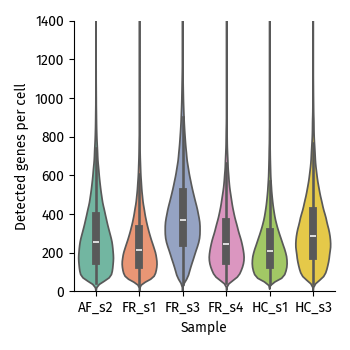

In [9]:
plt.figure(figsize=(3.5,3.5))
sns.violinplot(data=counts_df, x="sample", y="n_genes_by_counts", hue="sample", palette="Set2")
plt.ylim(0,1400)
plt.ylabel("Detected genes per cell")
plt.xlabel("Sample")
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(f"{WORK_PATH}Figure/011_QC_violin.png", dpi=300, format="png", bbox_inches=None)

# Initial Clustering of All Cells

In [1]:
import matplotlib.pyplot as plt
import matplotlib
import os
import numpy as np
import scanpy as sc
import anndata
import pandas as pd
from Xenium_5K_IPF_constants import MAJOR_CLUSTER_COLORS, WORK_PATH

os.makedirs(f"{WORK_PATH}Figure", exist_ok=True)
os.makedirs(f"{WORK_PATH}CSV", exist_ok=True)

# Option
sc.settings.verbosity = 3
%matplotlib ipympl
plt.rcParams["font.family"] = "Fira Sans" 


In [5]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/integrated_anndata.h5ad")

In [ ]:
print(f"Total cells: {len(adata.obs)}")
print(f"Total genes: {len(adata.var)}")
print(f"Total transcripts: {sum(adata.obs["total_counts"])}")

In [ ]:
# pearson_residual
adata.raw = adata.copy()
sc.experimental.pp.highly_variable_genes(adata, flavor="pearson_residuals", n_top_genes=1000, batch_key="sample")
sc.experimental.pp.normalize_pearson_residuals(adata)
sc.pp.pca(adata, n_comps=50, mask_var="highly_variable")

In [ ]:
# integrate with harmony
sc.external.pp.harmony_integrate(adata, "sample")
adata.obsm['X_pca'] = adata.obsm['X_pca_harmony']

In [ ]:
sc.pp.neighbors(adata, n_neighbors=50)
sc.tl.umap(adata, min_dist=0.1, spread=2.5)
sc.tl.leiden(adata, resolution=1.5, flavor="igraph", n_iterations=-1, directed=False)

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(6,6))
plt.subplots_adjust(left=0, right=1, bottom=0, top=1)
sc.pl.umap(adata,color="leiden", legend_loc="on data", s=3, ax=ax, legend_fontoutline=3, legend_fontsize=24)
ax.axis("off")
plt.savefig(f"{WORK_PATH}Figure/011_All_leiden_umap.png", dpi=300, format="png", bbox_inches=None)

In [ ]:
adata.layers["pearson"]=adata.X.copy()
adata.X=adata.raw.X.copy()

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [ ]:
deg_num = 1000
sc.tl.dendrogram(adata, groupby="leiden")
sc.tl.rank_genes_groups(adata, groupby="leiden", use_raw=False, n_genes=deg_num, method='wilcoxon')

In [ ]:
rg = adata.uns["rank_genes_groups"]
groups = list(rg["names"].dtype.names)  

In [ ]:
gene_to_col = {g: i for i, g in enumerate(adata.var_names)}

frac_by_group = {}
obs_grp = adata.obs["leiden"].values

for g in groups:
    mask = (obs_grp == g)
    n_cells = int(mask.sum())
    if n_cells == 0:
        frac_by_group[g] = np.zeros(adata.n_vars, dtype=float)
        continue

    subX = adata.X[mask, :].tocsr()
    hits = subX.copy()
    hits.data = (hits.data > 0).astype(np.int8)
    frac = np.asarray(hits.sum(axis=0)).ravel() / n_cells

    frac_by_group[g] = frac

In [ ]:
leiden_deg_df = pd.DataFrame(columns=[i for i in range(deg_num*len(groups))], index=["leiden", "genes", "fractions", 'scores', 'pvals', 'pvals_adj', 'logfoldchanges'])

for n, g in enumerate(groups):
    for i in range(deg_num):
        leiden_deg_df.loc["leiden", i+deg_num*n]=g
        leiden_deg_df.loc["genes", i+deg_num*n]=rg["names"][i][n]
        leiden_deg_df.loc["fractions", i+deg_num*n]=frac_by_group[g][gene_to_col[rg["names"][i][n]]]
        for t in ['scores', 'pvals', 'pvals_adj', 'logfoldchanges']:
            leiden_deg_df.loc[t, i+deg_num*n]=rg[t][i][n].astype(np.float64)
leiden_deg_df.T.to_csv(f"{WORK_PATH}CSV/011_leiden_degs.csv", index=False, encoding="utf-8-sig")

In [3]:
# Annotation
cluster_dict = {     
    "Epithelial": ["#E41A1C", [0, 1, 2, 3, 4, 7, 27]],
    "Fibroblast": ["#377EB8", [6, 13, 29, 35, 36]], 
    "SMC/Pericyte": ["#4DAF4A", [15, 17]], 
    "Endothelial": ["#984EA3", [8, 16, 24, 25]],  
    "CD8+ T": ["#FF1493", [9]], 
    "CD4+ T": ["#ADFF2F", [5]], 
    "Treg": ["#FFD92F", [10]], 
    "NK": ["#603A3A", [12]], 
    "B cell": ["#FC8D62", [34, 37]], 
    "Plasma cell": ["#E78AC3", [20, 21]],
    "Monocyte": ["#FFFA01", [28]], 
    "Macrophage": ["#FF7F00", [19, 22, 23, 32]], 
    "pDC": ["#00FFFF", [33]], 
    "cDC1": ["#8B008B", [39]], 
    "cDC2": ["#E5C494", [26]], 
    "mregDC": ["#0000CD", [18]], 
    "FRC-like": ["#A65628", [11]], 
    "FDC-like": ["#8DA0CB", [38]],    
    "Neutrophil": ["#008080", [30, 31]], 
    "Mast cell": ["#66C2A5", [14]]
}

cluster_lei2key = {}
for cl, [_, le] in cluster_dict.items():
    for l in le:
        cluster_lei2key[str(l)] = cl
cluster_lei2key_sort = {}
for l in range(len(adata.obs["leiden"].unique())):
    cluster_lei2key_sort[str(l)] = cluster_lei2key[str(l)]
adata.obs['cell_type'] = adata.obs['leiden'].map(cluster_lei2key_sort).astype('category')
adata.obs['cell_type'] = pd.Categorical(values=adata.obs['cell_type'], categories=list(cluster_dict), ordered=True)
adata.uns["cell_type_colors"] =[vals[0] for _, vals in cluster_dict.items()]

In [4]:
# Label position correction
legend_mdf = {
    "5": (-0.5, 0.5),
    "6": (-1, -1),
    "7": (-1, 0),
    "8": (1.5, -0.8),
    "11": (0, -1.4),
    "12": (1, 3.7),
    "13": (2.2, 1),
    "14": (-1, -1),
    "15": (2.8, 0),
    "16": (0, -1),
    "19": (5.5, -0.3),
}

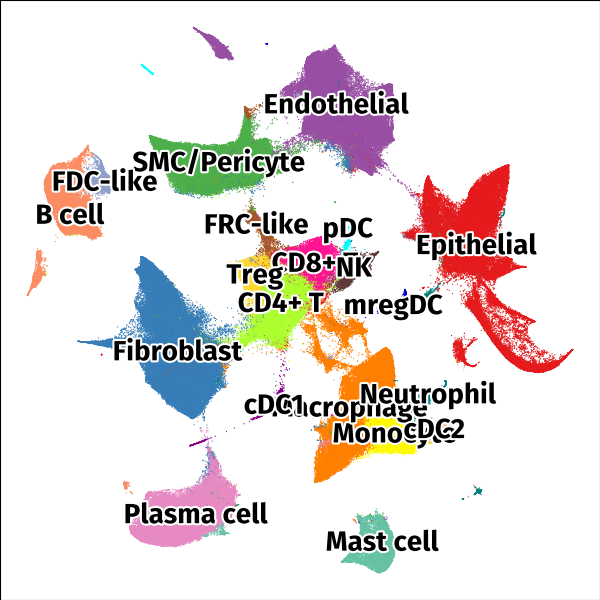

In [5]:
fig, ax = plt.subplots(1,1, figsize=(6,6))
plt.subplots_adjust(left=0, right=1, bottom=0, top=1)
sc.pl.umap(adata,color="cell_type", legend_loc="on data", s=3, ax=ax, legend_fontoutline=3, legend_fontsize=20)

for key, (x,y) in legend_mdf.items():
    chi = ax.get_children()[int(key)]
    chi.set_position((chi.get_position()[0]+x, chi.get_position()[1]+y))

plt.title("")
plt.axis("off")
plt.savefig(f"{WORK_PATH}Figure/011_All_celltype_umap.png", dpi=300, format="png", bbox_inches=None)

In [6]:
major_cluster_dict={
    "Epithelial": "Epithelial",
    "Fibroblast": "Fibroblast",
    "SMC/Pericyte": "SMC/Pericyte",
    "Endothelial": "Endothelial",
    "Monocyte": "Monocyte/MΦ",
    "Macrophage": "Monocyte/MΦ",

    "CD4+ T": "NK/T cell",
    "CD8+ T": "NK/T cell",
    "Treg": "NK/T cell",
    "NK": "NK/T cell",

    "B cell": "B/Plasma cell",
    "Plasma cell": "B/Plasma cell",
    
    "pDC": "Dendritic cell",
    "cDC1": "Dendritic cell",
    "cDC2": "Dendritic cell",
    "mregDC": "Dendritic cell",
    
    "Neutrophil": "Granulocyte",
    "Mast cell": "Granulocyte",

    "FRC-like": "TLS-associated",
    "FDC-like": "TLS-associated",

}

In [7]:
adata.obs['cell_type_major'] = adata.obs['cell_type'].map(major_cluster_dict).astype('category')
adata.obs['cell_type_major'] = pd.Categorical(values=adata.obs['cell_type_major'], categories=list(MAJOR_CLUSTER_COLORS), ordered=True)
adata.uns["cell_type_major_colors"] = list(MAJOR_CLUSTER_COLORS.values())

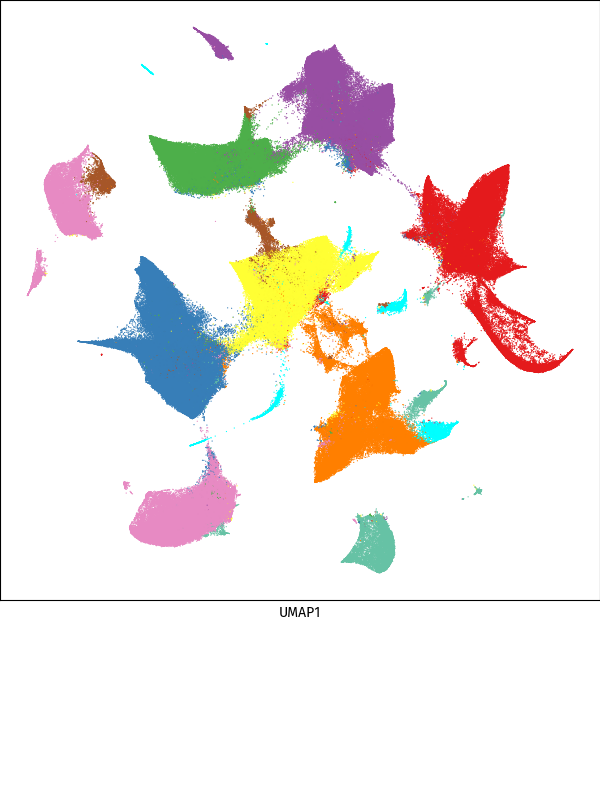

In [32]:
fig, ax = plt.subplots(1,1, figsize=(6,8))
plt.subplots_adjust(left=0, right=1, bottom=0.25, top=1)
sc.pl.umap(adata,color="cell_type_major", s=3, ax=ax)
ax.legend(markerscale=2.5, fontsize=18, bbox_to_anchor=(0.5, 0.02), loc="upper center", edgecolor="white", handletextpad=0.2, ncols=2)

plt.title("")
plt.axis("off")

plt.savefig(f"{WORK_PATH}Figure/011_All_celltypeM_umap.png", dpi=500, format="png", bbox_inches=None)

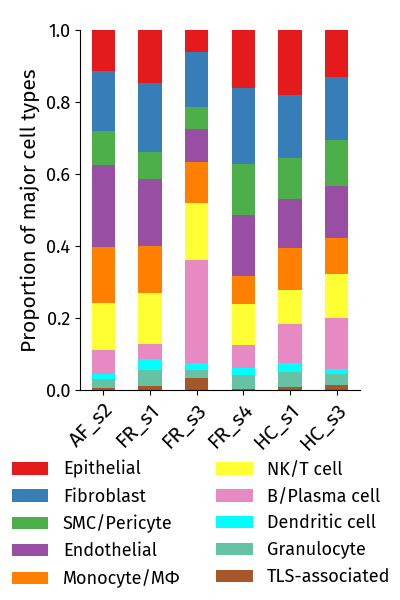

In [3]:
ct_counts = pd.crosstab(adata.obs['sample'], adata.obs['cell_type_major'])
ct_props = ct_counts.div(ct_counts.sum(axis=1), axis=0)

cell_type_order = ct_counts.columns.tolist()
ct_props = ct_props[cell_type_order[::-1]]

colors = adata.uns["cell_type_major_colors"]
colors_for_plot = colors[::-1]

ax = ct_props.plot(kind='bar', stacked=True, figsize=(4, 6), color=colors_for_plot)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], title='', bbox_to_anchor=(-0.3, -0.15), loc='upper left', fontsize=13, edgecolor="white", ncols=2)

plt.ylabel('Proportion of major cell types', fontsize=15)
plt.xlabel('')
plt.ylim(0,1)
plt.xticks(size=15, rotation=45, rotation_mode='anchor', ha="right", va="top")

plt.tick_params("y", labelsize=13)
plt.subplots_adjust(left=0.2,bottom=.35, top=0.95)
plt.savefig(f"{WORK_PATH}Figure/011_All_sample_stackedbar.png", dpi=500, format="png", bbox_inches=None)

In [11]:
ct_props = ct_props[cell_type_order[:]]

df_source = pd.DataFrame(index=ct_props.index, columns=ct_props.columns)

for col in ct_props.columns:
    df_source[col] = [
        f"{p * 100:.2f}% ({n:,})"
        for p, n in zip(ct_props[col], ct_counts.loc[ct_props.index, col])
    ]

df_source.index.name = "Sample"
df_source.to_csv(f"{WORK_PATH}CSV/011_All_sample_stackedbar_source_data.csv", index=True)

In [11]:
adata.write(f"{WORK_PATH}AnnData/1st_clustering.h5ad")

In [10]:
celltype_df = adata.obs[["cell_type", "cell_type_major", "sample"]].copy()
celltype_df["cell_id"] = celltype_df.index
celltype_df.set_index("cell_id", inplace=True)
celltype_df.to_csv(f"{WORK_PATH}CSV/011_1st_clustering.csv", index=True, encoding="utf-8-sig")

In [3]:
# Preparing feature plots for marker genes
cmap = matplotlib.colormaps["inferno"].copy()
cmap.set_under("lightgrey") 
row, col=3, 4

gene_sets = {
        "EPCAM": ("Epithelial", 8), "CDH1": ("Epithelial", 8), "DHCR24": ("Epithelial", 15),
        "COL5A1": ("Fibroblast", 40), "PDGFRA": ("Fibroblast", 7), "NBL1": ("Fibroblast", 50),
        "PLN": ("SMC/Pericyte", 10), "NOTCH3": ("SMC/Pericyte", 10),
        "CLDN5": ("Endothelial", 15), "SHANK3": ("Endothelial", 15),
        "CXCR4": ("Immune cell", 12), "ITGAL":("Immune cell",4), 
}
print(len(gene_sets))

12


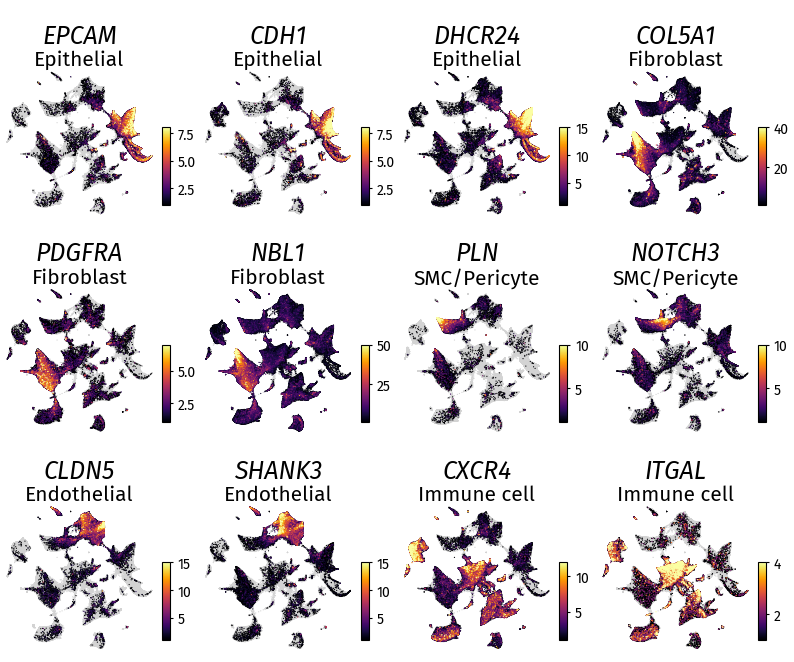

In [4]:
# UMAP of marker gene expression

umap_box = 1.7
umap_spa = [0.25, 0.4]
fig, axes = plt.subplots(row, col, figsize=((col*umap_box + (col-1)*umap_spa[0])/0.95,(row*umap_box + (row-1)*umap_spa[1])/0.89))
fig.subplots_adjust(left=0, right=0.95, top=0.9, bottom=0.01, wspace=umap_spa[0], hspace=umap_spa[1])
axes = axes.flatten()

for ax, (key, val) in zip(axes, gene_sets.items()):
    sc.pl.umap(
        adata,
        color=key,
        s=3,
        show=False,
        colorbar_loc=None,
        cmap=cmap,
        vmin=1, 
        vmax = val[1],
        ax = ax,
    )
    ax.axis("off")
    ax.set_title("")
    ax.text(0.5, 1.11, key, transform=ax.transAxes, ha="center", va="bottom", fontsize=18, fontdict={"style":"italic"})
    ax.text(0.5, 1.1, val[0], transform=ax.transAxes, ha="center", va="top", fontsize=15)

    norm = matplotlib.colors.Normalize(vmin=1, vmax=val[1])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cbar_ax = fig.add_axes([
        ax.get_position().width*0.02+ax.get_position().x1, 
        ax.get_position().height*0.1+ax.get_position().y0, 
        ax.get_position().width*0.05, 
        ax.get_position().height/2
    ])
    fig.colorbar(sm, cax=cbar_ax)
    cbar_ax.tick_params("y", size=2)

plt.savefig(f"{WORK_PATH}Figure/011_1st_clustering_umap_cellmarker_genes.png", dpi=500, format="png", bbox_inches=None)

# Spatial Merging

In [ ]:
import spatialdata as sd
import anndata
import pandas as pd
import squidpy as sq
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from Xenium_5K_IPF_constants import SAMPLES_SYMBOLS, WORK_PATH

# Constant Declaration
sample_ws = 10000
sample_hs = 7000

r = 300 # Radius of cell-cell interaction analysis

%matplotlib ipympl

In [ ]:
adata_list=[]

for n, s in enumerate(SAMPLES_SYMBOLS):
    # Loading SpatialData
    sp_adata = sd.SpatialData.read(f"{WORK_PATH}SpatialData/{s}")
    adata = sp_adata.tables["table"]
    adata.obs_names = [adata.obs["cell_id"].iloc[m][:-1]+str(n) for m in range(len(adata.obs))]
    adata.obs["sample"]=s
    adata_list.append(adata)
    del sp_adata, adata

In [ ]:
xy_range_max = [0.0, 0.0]

for ad in adata_list:
    xy = ad.obsm["spatial"]
    x_min, y_min = xy.min(axis=0)
    x_max, y_max = xy.max(axis=0)

    xy_range_max[0] = max(xy_range_max[0], float(x_max - x_min))
    xy_range_max[1] = max(xy_range_max[1], float(y_max - y_min))

margin_x = sample_ws - xy_range_max[0]
margin_y = sample_hs - xy_range_max[1]

if (margin_x > 0) and (margin_y > 0):
    max_radius = min(margin_x, margin_y)
    print(
        f"With the current per-sample offsets, the maximum safe radius for the cell–cell interaction analysis "
        f"is {max_radius:.0f} µm (to prevent overlap between samples)."
    )
elif (margin_x <= 0) and (margin_y <= 0):
    print("Increase both sample_wd and sample_ht to prevent overlap between samples.")
elif margin_x <= 0:
    print("Increase sample_wd (the per-sample X offset) to prevent overlap between samples along the X-axis.")
else:  # margin_y <= 0
    print("Increase sample_ht (the per-sample Y offset) to prevent overlap between samples along the Y-axis.")


In [ ]:
"""
Arrange as below.
Do not place samples too close together.

  x-->
y FR_s1 HC_s1 AF_s2
| FR_s3 HC_s3 FR_s4
V 

Assign a virtual distance based on the position of A1.
"""

# AF_s2
adata_list[0].obsm["spatial"][:, 0] += sample_ws * 2
# adata_list[0].obsm["spatial"][:, 1] += sample_hs * 0 

# FR_s1
# adata_list[1].obsm["spatial"][:, 0] += sample_ws * 0
# adata_list[1].obsm["spatial"][:, 1] += sample_hs * 0

# FR_s3
# adata_list[2].obsm["spatial"][:, 0] += sample_ws * 0
adata_list[2].obsm["spatial"][:, 1] += sample_hs * 1

# FR_s4
adata_list[3].obsm["spatial"][:, 0] += sample_ws * 2
adata_list[3].obsm["spatial"][:, 1] += sample_hs * 1

# HC_s1
adata_list[4].obsm["spatial"][:, 0] += sample_ws * 1
# adata_list[4].obsm["spatial"][:, 1] += sample_hs * 0

# HC_s3
adata_list[5].obsm["spatial"][:, 0] += sample_ws * 1
adata_list[5].obsm["spatial"][:, 1] += sample_hs * 1

In [ ]:
adata = anndata.concat(adata_list, merge="same")

In [ ]:
# confirmation
fig, ax = plt.subplots(figsize=(6,3))
sq.pl.spatial_scatter(adata, color="sample", library_id="spatial", shape=None, size=1, ax=ax)

# plot circle of an analysis range example
c = patches.Circle(xy=(8000, 6000), radius=r, fc='yellow', ec='red')
ax.add_patch(c)

fig.tight_layout()

In [ ]:
adata.write(f"{WORK_PATH}AnnData/spatial_merged.h5ad")